# 00 · 了解 FinMCP-Bench

FinMCP-Bench 是我们主实验的基准。这一本从数据本身出发，带你看清楚它：**它是怎么来的、里面有什么、一条任务长什么样、工具和返回结果是什么样、怎么评测**，最后落到和我们研究直接相关的问题：**哪些任务含有需要语义判断的依赖**。

| 项目 | 内容 |
| --- | --- |
| 论文 | *FinMCP-Bench: Benchmarking LLM Agents for Real-World Financial Tool Use under the Model Context Protocol*，ICASSP 2026，arXiv:2603.24943 |
| 作者 | 阿里云通义点金团队、盈米基金（且慢）、苏州大学 |
| 数据 | HuggingFace `DianJin/FinMCP-Bench`，本地在 `../finmcp-analysis/data/` |
| 语言 | 中文（多轮子集的场景标签是英文） |
| 工具 | 且慢 App 金融助手「小顾」背后的 MCP 工具 |
| 许可 | **CC BY-NC-SA 4.0**：仅限非商业用途，衍生数据须以相同许可发布 |

**这一本只读本地数据，不调用任何接口，不花钱。**

In [1]:
%pip install -q -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import collections, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from jif import finmcp

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 60)

# 图表样式：单系列用一个主色，网格和坐标轴弱化；中文字体自动选可用的
CJK = next((n for n in ["PingFang SC", "Hiragino Sans GB", "Heiti SC", "Microsoft YaHei", "SimHei",
                        "Noto Sans CJK SC", "Source Han Sans SC", "Arial Unicode MS"]
            if n in {f.name for f in font_manager.fontManager.ttflist}), None)
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [CJK] if CJK else ["DejaVu Sans"], "axes.unicode_minus": False,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": "#0b0b0b", "axes.titlelocation": "left"})
SERIES, SURFACE = "#2a78d6", "#fcfcfb"
if CJK is None:
    print("没有找到中文字体，图中的中文可能显示为方块")

def hbar(series, title, xlabel):
    s = series.sort_values()
    fig, ax = plt.subplots(figsize=(7.5, 0.34 * len(s) + 1.0))
    ax.barh(s.index, s.values, color=SERIES, height=0.62)
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    plt.tight_layout()
    plt.show()

SPLITS = {"single_tool": "单工具", "multi_tool": "多工具", "multi_turn": "多轮"}
data = {k: finmcp.load_split(k) for k in SPLITS}
pd.DataFrame([{"子集": SPLITS[k], "文件": finmcp.SPLITS[k], "样本数": len(v)} for k, v in data.items()])

,子集,文件,样本数
0,单工具,benchmark_single_tool.json,145
1,多工具,benchmark_multi_tool.json,249
2,多轮,benchmark_multi_turn.json,219


## 1. 三个子集与字段

| 子集 | 定义（论文） | 样本 |
| --- | --- | --- |
| 单工具 | 一轮对话、一次工具调用就能解决 | 145 |
| 多工具 | 一轮对话、多次工具调用，可能串行也可能并行 | 249 |
| 多轮 | 多轮对话，每轮可能调用零到多个工具 | 219 |

每条样本有 6 个字段：

In [3]:
s = data["multi_tool"][0]
fields = {
    "scenery": "场景，三级或两级，用短横线连接，如 市场分析与研究-海外市场-全球资产配置",
    "diff_level": "难度信息：turns 对话轮数、tool_number 工具调用数、para_tool_call_number 并行调用数、level 难度",
    "tool_list": "按调用顺序列出的工具名（每一步一个列表）",
    "question": "用户的问题（多工具子集里带有\"当前用户id是…\"）",
    "messages": "完整的参考轨迹：user / assistant（含 tool_calls）/ tool 消息，多轮子集还有 system 消息",
    "task": "子集类型：single step / multi step / multi turn",
}
pd.DataFrame([{"字段": k, "含义": v, "示例": json.dumps(s[k], ensure_ascii=False)[:80]} for k, v in fields.items()])

,字段,含义,示例
0,scenery,场景，三级或两级，用短横线连接，如 市场分析与研究-海外市场-全球资产配置,"""市场分析与研究-海外市场-全球资产配置"""
1,diff_level,难度信息：turns 对话轮数、tool_number 工具调用数、para_tool_call_number 并行调用数、level 难度,"{""turns"": 1, ""tool_number"": 5, ""para_tool_call_number"": 0, ""level"": ""easy""}"
2,tool_list,按调用顺序列出的工具名（每一步一个列表）,"[[""GetUserInfo""], [""GetUserAssetView""], [""GetStrategyAssetClassAnalysis""], [""Get"
3,question,"用户的问题（多工具子集里带有""当前用户id是…""）","""帮我推荐海外资产配置策略\n当前用户id是9b9b9a9c929a9c"""
4,messages,完整的参考轨迹：user / assistant（含 tool_calls）/ tool 消息，多轮子集还有 system 消息,"[{""content"": ""帮我推荐海外资产配置策略\n当前用户id是9b9b9a9c929a9c"", ""role"": ""user""}, {""role"": ""a"
5,task,子集类型：single step / multi step / multi turn,"""multi step"""


## 2. 数据是怎么来的

这一点决定了我们怎么解读"参考答案"，所以放在前面（以下据论文）：

1. **单工具：来自真实日志。** 从「小顾」的 1 万条历史日志里，筛出问题是真实金融需求、靠工具调用解决、最终回答令人满意的样本，得到 1,484 条单工具样本，最终保留 145 条。
2. **多工具：合成。** 先根据工具的共现关系建一张**工具依赖图（65 个节点、288 条边）**，由 Qwen3-235B 判断依赖是否合理；再在图上采样工具链，让模型生成匹配的问题，并连接 MCP 服务实际执行得到轨迹。生成约 1 千条，专家审核后保留 249 条。
3. **多轮：角色扮演合成。** 由 Qwen3-235B 同时扮演用户和助手，用户画像来自人物模板，目标按子场景生成。生成 500 条，自动校验和专家审核后保留 219 条。
4. **质检**：6 位领域专家按 5 个维度、5 分制打分，两位独立评审都给出 4 分以上才保留。

**对我们的含义**

- 多工具和多轮的参考轨迹是**模型生成、专家把关**的，不是唯一正确答案。比如"推荐几个策略"时选了 4 个里的哪 1 个，带有随意性。评测时要允许合理的不同选择。
- 工具返回是**连接真实 MCP 服务执行得到的**，数据是真实的（截至 2025 年 8 月前后）。
- 论文自己也用了"工具依赖图"来造数据，这和我们 SOG 里的操作图是同一类东西，可以在论文里对照。

## 3. 难度与规模

论文按工具调用次数分难度：**easy ≤ 5 次，medium ≤ 10 次，hard 更多**。

In [4]:
rows = []
for k, items in data.items():
    for i, t in enumerate(items):
        calls = finmcp.tool_calls(t)
        steps = sum(1 for m in t["messages"] if m["role"] == "assistant" and m.get("tool_calls"))
        rows.append({"子集": SPLITS[k], "task_id": f"{k}:{i}", "难度": t["diff_level"].get("level"),
                     "对话轮数": sum(1 for m in t["messages"] if m["role"] == "user"),
                     "工具调用数": len(calls), "调用步数": steps,
                     "有并行调用": any(len(m.get("tool_calls") or []) > 1 for m in t["messages"] if m["role"] == "assistant"),
                     "不同工具数": len({c["name"] for c in calls})})
tasks = pd.DataFrame(rows)
display(pd.crosstab(tasks["子集"], tasks["难度"], margins=True, margins_name="合计")[["easy", "medium", "hard", "合计"]])
tasks.groupby("子集")[["对话轮数", "工具调用数", "调用步数", "不同工具数", "有并行调用"]].agg(["mean", "median", "max"]).round(2)

难度,easy,medium,hard,合计
子集,,,,
单工具,145,0,0,145
多工具,98,138,13,249
多轮,100,107,12,219
合计,343,245,25,613


对话轮数            工具调用数             调用步数            不同工具数            有并行调用  \
     mean median max  mean median max  mean median max  mean median max  mean   
子集                                                                              
单工具  1.00    1.0   1  1.00    1.0   1  1.00    1.0   1  1.00    1.0   1  0.00   
多工具  1.00    1.0   1  7.34    8.0  18  5.73    5.0  18  6.15    6.0  13  0.29   
多轮   5.95    6.0  13  5.00    4.0  20  5.00    4.0  20  3.86    3.0  11  0.00   

                   
    median    max  
子集                 
单工具    0.0  False  
多工具    0.0   True  
多轮     0.0  False

多工具子集平均 7.3 次调用、5.7 步（一步里可以并行发出多个调用）；多轮子集平均 6 轮对话。下面看每个任务的调用次数分布，三个子集各画一个小图：

findfont: Failed to find font weight bold for PingFang SC, now using 600.


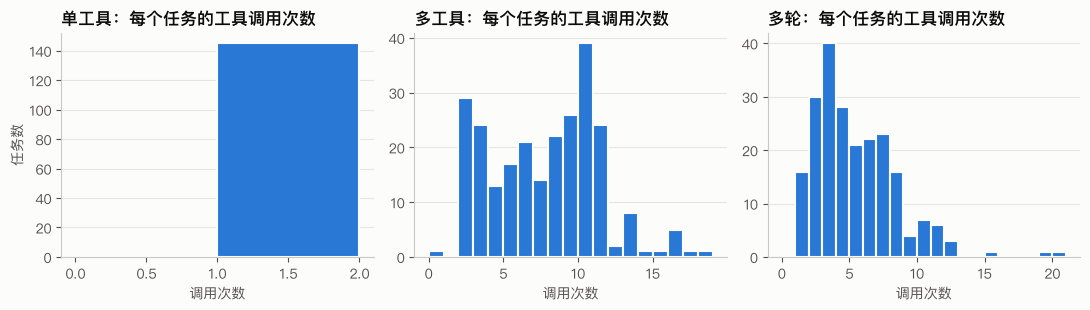

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, (k, name) in zip(axes, SPLITS.items()):
    v = tasks[tasks["子集"] == name]["工具调用数"]
    ax.hist(v, bins=range(0, v.max() + 2), color=SERIES, edgecolor=SURFACE, linewidth=1.5)
    ax.set_title(f"{name}：每个任务的工具调用次数")
    ax.set_xlabel("调用次数")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("任务数")
plt.tight_layout()
plt.show()

## 4. 场景

场景分三级（如 *市场分析与研究 - 海外市场 - 全球资产配置*）。多轮子集用的是英文标签，这里统一翻译成中文。一共 10 个一级场景，其中"合规与法律"只出现在多轮子集里。

子集,单工具,多工具,多轮,合计
一级场景,,,,
合计,145,249,219,613
市场分析与研究,67,47,27,141
投资规划与配置,5,49,47,101
交易执行与操作,18,46,32,96
投资者教育,18,18,35,71
产品与策略咨询,24,19,8,51
账户与服务管理,8,24,15,47
平台技术支持,3,19,9,31
其他咨询,0,12,18,30


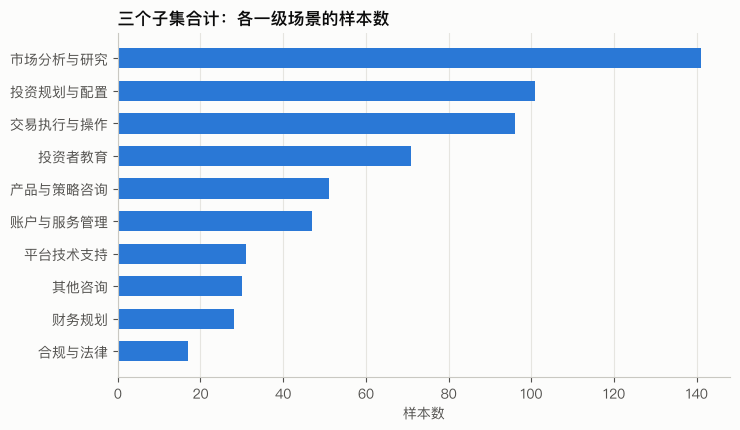

In [6]:
EN2ZH = {"InvestmentPlanningAndAllocation": "投资规划与配置", "InvestorEducation": "投资者教育",
         "TradeExecutionAndOperations": "交易执行与操作", "MarketAnalysisAndResearch": "市场分析与研究",
         "OtherInquiries": "其他咨询", "ComplianceAndLegal": "合规与法律", "AccountAndServiceManagement": "账户与服务管理",
         "FinancialPlanning": "财务规划", "PlatformTechnicalSupport": "平台技术支持",
         "ProductAndStrategyConsultation": "产品与策略咨询"}
scen = pd.DataFrame([{"子集": SPLITS[k], "一级场景": EN2ZH.get(t["scenery"].split("-")[0], t["scenery"].split("-")[0]),
                      "二级场景": t["scenery"].split("-")[1] if "-" in t["scenery"] else ""}
                     for k, items in data.items() for t in items])
table = pd.crosstab(scen["一级场景"], scen["子集"], margins=True, margins_name="合计").sort_values("合计", ascending=False)
display(table)
hbar(table.drop("合计")["合计"], "三个子集合计：各一级场景的样本数", "样本数")

In [7]:
print("二级场景示例：")
scen[scen["二级场景"] != ""].groupby("一级场景")["二级场景"].agg(lambda x: "、".join(pd.Series(x).value_counts().index[:6]))

二级场景示例：


一级场景
交易执行与操作                                投资结果查询、TradeExecutionGuidance、交易操作指导、成本费用咨询、收益分配、CostAndFeeConsultation
产品与策略咨询                                      策略产品详情、StrategyProductDetails、PrivateEquityAndInsuranceCategories
其他咨询                                                         NonAdvisoryInquiries、非投顾相关咨询、EmotionalExpressions
合规与法律                                                                                  TaxOptimizationAdvisory
市场分析与研究                                                                  基金分析、海外市场、行业分析、资产趋势、宏观经济、FundAnalysis
平台技术支持                       操作指导、平台功能使用、系统技术问题、PlatformFeatureUsage、SystemTechnicalIssues、OperationalGuidance
投资者教育      产品知识介绍、ProductKnowledgeIntroduction、BasicInvestmentKnowledge、基础投资知识、MarketAwarenessEnhancement、市...
投资规划与配置                     持仓优化、PersonalizedInvestmentStrategies、RegularInvestmentPlans、个性化投资方案、定期投资计划、资产配置建议
财务规划                                           退休规划、RetirementPlanning、GoalPlanning、目标规划、专项规划、ThematicPlann

## 5. 工具

论文说全部 65 个工具，平均每个 2.6 个参数。参考轨迹里实际用到的工具如下。**数据集没有附带工具的参数定义**（需要从且慢开通 MCP 后获取），下面的参数信息是从调用日志里统计出来的。

用到的不同工具： 56 个；工具调用总数： 3068


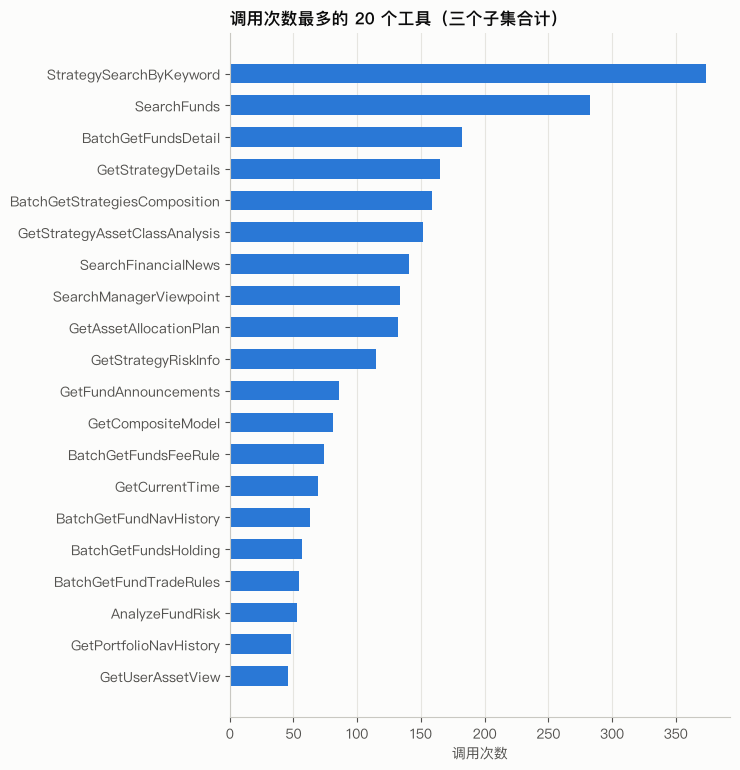

In [8]:
calls = pd.DataFrame([{"子集": SPLITS[k], "task_id": f"{k}:{i}", "工具": c["name"], "参数": c["args"],
                       "返回字符数": len(c["text"] or ""), "返回类型": type(c["json"]).__name__}
                      for k, items in data.items() for i, t in enumerate(items) for c in finmcp.tool_calls(t)])
print("用到的不同工具：", calls["工具"].nunique(), "个；工具调用总数：", len(calls))
freq = calls["工具"].value_counts()
hbar(freq.head(20), "调用次数最多的 20 个工具（三个子集合计）", "调用次数")

In [9]:
def arg_summary(group):
    c = collections.Counter(a for args in group for a in args)
    n = len(group)
    return "，".join(f"{a}({v / n:.0%})" for a, v in c.most_common(6))

def family(name):
    for prefix, label in (("Search", "检索"), ("BatchGet", "批量查询"), ("Get", "查询"), ("Analyze", "分析计算"),
                          ("Render", "渲染"), ("Diagnose", "诊断"), ("Guess", "识别")):
        if name.startswith(prefix):
            return label
    return "其他"

tool_table = (calls.groupby("工具").agg(调用次数=("参数", "size"), 参数及出现比例=("参数", arg_summary),
                                       返回字符中位数=("返回字符数", "median"))
              .sort_values("调用次数", ascending=False))
tool_table.insert(0, "类别", [family(n) for n in tool_table.index])
tool_table["需要用户身份"] = calls.groupby("工具")["参数"].apply(lambda g: any("userId" in a for a in g))
tool_table

,类别,调用次数,参数及出现比例,返回字符中位数,需要用户身份
工具,,,,,
StrategySearchByKeyword,其他,374,keyword(100%)，pageSize(26%)，pageNum(24%)，category(0%)，size(0%),365.0,False
SearchFunds,检索,283,keyword(69%)，size(69%)，sortColumn(54%)，sortOrder(54%)，category(46%)，page(33%),1225.0,False
BatchGetFundsDetail,批量查询,182,fundCodes(100%),9517.0,False
GetStrategyDetails,查询,165,strategyCodes(100%)，pageNum(21%)，pageSize(21%),945.0,False
BatchGetStrategiesComposition,批量查询,159,strategyCodes(100%),10237.0,False
GetStrategyAssetClassAnalysis,查询,152,strategyCode(100%),3823.0,False
SearchFinancialNews,检索,141,keyword(99%)，pageSize(65%)，page(60%)，startDate(28%)，endDate(28%)，size(1%),1347.0,False
SearchManagerViewpoint,检索,134,keyword(99%)，pageSize(46%)，page(39%)，startDate(35%)，endDate(35%)，author(1%),3685.5,False
GetAssetAllocationPlan,查询,132,expectedInvestTime(91%)，expectedAnnualizedReturnRate(58%)，expectedDrawdown(53%),553.0,False


几点观察：

- **工具大致分几类**：检索（`StrategySearchByKeyword`、`SearchFunds`、`SearchFinancialNews`）、批量查询（`BatchGetFundsDetail` 等，参数是代码列表）、用户资产（需要 `userId`）、分析计算（`AnalyzeFundRisk`、`MonteCarloSimulate` 等）、渲染（`RenderHtmlToPdf`）。
- **典型的依赖链**是"先检索拿到代码，再用代码批量查询"，例如 `StrategySearchByKeyword → GetStrategyDetails`、`SearchFunds → BatchGetFundsDetail`。中间那一步"从检索结果里挑哪些代码"，正是我们说的语义判断。
- 字段名中英混杂：同一个基金代码，有的工具叫 `fundCode`，有的叫 `基金代码`。这就是 01 号 notebook 里属性对齐要解决的问题。

## 6. 看三条样本

用一个函数把轨迹打印成易读的样子：每次工具调用、返回结果的开头，以及最后的回答。

In [10]:
def show(task_id, max_chars=300):
    t = finmcp.get_task(task_id)
    print(f"【{task_id}】场景：{t['scenery']}  难度：{t['diff_level']}")
    results = {m.get("tool_call_id"): m.get("content") or "" for m in t["messages"] if m["role"] == "tool"}
    for m in t["messages"]:
        if m["role"] == "system":
            print(f"\n[system] {(m['content'] or '')[:max_chars]}…")
        elif m["role"] == "user":
            print(f"\n[用户] {m['content']}")
        elif m["role"] == "assistant" and m.get("tool_calls"):
            for c in m["tool_calls"]:
                text = results.get(c.get("id"), "")
                print(f"  → 调用 {c['function']['name']}({c['function']['arguments']})")
                print(f"    ← 返回 {len(text)} 字符：{' '.join(text.split())[:max_chars]}")
        elif m["role"] == "assistant":
            print(f"\n[助手] {' '.join((m['content'] or '').split())[:max_chars * 2]}")

show("single_tool:0")

【single_tool:0】场景：市场分析与研究-宏观经济-市场环境研判  难度：{'turns': 1, 'tool_number': 1, 'para_tool_call_number': 0, 'level': 'easy'}

[用户] 最近市场行情如何？
当前用户id是9b989c9e999b92
  → 调用 SearchFinancialNews({"keyword": "市场"})
    ← 返回 13232 字符：{ "success": true, "data": { "total": 20, "page": 1, "pageSize": 20, "totalPages": 1, "items": [ { "id": 7868111, "title": "观半年项目，知全年基建【宏观视界第24期】", "summary": "这是华创证券研究所发布的“宏观视界第24期”内容，主题为“观半年项目，知全年基建”。资料仅面向华创证券客户中的金融机构专业投资者，普通投资者使用可能产生理解歧义与投资损失。资料来自已发布研究报告，其观点和推测可能更改，证券价格等有涨跌风险。强调订阅人不应单纯依靠资料信息，应自主决

[助手] 根据最新财经资讯，当前市场呈现以下特点： ### 一、股市动态 1. **整体走势**：A股三大指数集体收涨，上证指数逼近3700点关键关口（8月15日收报3696.77点），创业板指单日大涨2.61%，两市成交额达2.24万亿元。主力资金净流入23.6亿元，非银金融、电力设备、计算机板块领涨。 2. **热点板块**： - **液冷概念**爆发式增长，欧陆通单周暴涨83%，户均浮盈超70万元。受益于AI算力需求激增，2024年中国液冷服务器市场规模达23.7亿美元，预计2025年渗透率将超50%。 - **机器人概念**卷土重来，Robotaxi领域多空博弈激烈，"木头姐"旗下ARK基金重仓布局。 3. **市场分化**：小盘成长风格占优，周期板块（有色金属、机械）表现强势，大消费板块相对疲软。 ### 二、债市表现 - 中债综合指数净价下跌0.0712%，10年期国债收益率上行1BP至1.75%。 - 信用债表现优于利率债，中高等级信用债利差收窄，绿色债券市场保持正回报。 ### 三、政策与行业 1. **房地产**：多地出台稳

In [11]:
show("multi_tool:30")

【multi_tool:30】场景：投资规划与配置-持仓优化-持仓结构分析  难度：{'turns': 1, 'tool_number': 3, 'para_tool_call_number': 1, 'level': 'easy'}

[用户] 我有买长赢和稳稳的幸福吗
当前用户id是9b989f9b9d9b92
  → 调用 StrategySearchByKeyword({"keyword": "长赢"})
    ← 返回 3927 字符：{ "pageSize": 20, "rows": [ { "策略代码": "LONG_WIN", "策略名称": "长赢指数投资计划-150份", "策略风险等级": "中高风险", "策略简介": "将整体风险控制在一个很低水平的前提下，通过投资指数，在牛市中实现资产大幅增值。如果你能够接受这样的投资世界观：慢慢买入便宜的指数基金，慢慢等待开花结果。过程中即使有暴风骤雨也微笑面对，那么，我很欢迎你参考我的计划", "策略描述": null, "策略成立时间": "2015-07-01" }, { "策略代码": "LONG_WIN_S", "策略名称": "长赢指数投资计划-S定投", "
  → 调用 StrategySearchByKeyword({"keyword": "稳稳的幸福"})
    ← 返回 407 字符：{ "pageSize": 20, "rows": [ { "策略代码": "ZH013136", "策略名称": "我要稳稳的幸福", "策略风险等级": "中低风险", "策略简介": "在有效控制风险基础上，把握大类资产配置机会，实现资产长期增值。基金配置仓位动态调整，应对各类市场环境变化。本组合适合追求稳健收益的投资人，建议持有1年以上。", "策略描述": "严控净值回撤，力求获得最佳收益风险比，目标年化收益率6%-8%。传统投资方法首先考虑“收益”，本组合更关注控制“风险”：通过量化模型和主动择时相结合，进行大量资产配置和优选基金，平滑市场波动。", "策略成立时间": "2017
  → 调用 GetUserAssetHoldingDistribution({"userId": "9b989f9b9d9b92", "poCodes": ["LONG_WIN", "ZH000095",

In [12]:
show("multi_turn:0", max_chars=200)

【multi_turn:0】场景：AccountAndServiceManagement-CustomerServiceSupport  难度：{'turns': 4, 'tool_number': 2, 'level': 'easy'}

[system] # Fin agent policy

作为金融服务代理（Fin Agent），您可以利用提供的MCP工具解决任务，MCP工具名称及相关参数列表保存在qieman_tool_schema.json文件中，请从这个文件中获取相关信息。注意，你只能调用这个文件中存在的工具，不得编造或调用qieman_tool_schema.json中不存在的工具。

- 在对话开始时，请先与用户进行简单交流，了解用户…

[用户] 你好，我是住在浙江杭州的Noah Brown。我想问一下，6月3日我放入盈米宝的100元，为什么到现在还没有产生收益？这让我有点着急，能不能帮我查一下原因？

[助手] 您好，Noah Brown！很高兴为您服务。为了更好地解决您的问题，我需要先确认一些信息。 您提到的资金是6月3日放入盈米宝的100元，目前未产生收益。为了查明原因，我需要检查该日期的资金流动情况和收益计算规则。我需要调用一些工具来获取相关信息，比如资金流分析和收益计算规则。 在继续之前，能否确认一下您的账户是否已经正确绑定，并且您使用的是正确的基金代码或产品名称？另外，请确认您查看收益的时间是否已经过了收益计算的确认期，因为有些产品会在交易后的T+1日或更长时间才确认份额并开始计算收益。

[用户] 我确认账户是绑定好的，基金代码和产品名称应该也没问题。盈米宝我之前也用过一段时间，没出现过这种情况。不过你说的收益计算确认期我倒是不太清楚，难道是这个原因？可我之前放进去的钱第二天就能看到收益了啊，为什么这次都过去这么久了还是没有动静？
  → 调用 BatchGetFundTradeRules({"fundCodes": ["Y10001"], "op": "allot", "txnTime": "2024-06-03 10:00:00"})
    ← 返回 105 字符：[ { "fundCode": "Y10001", "error": "未找到该基金", "url": "https://qieman.com/funds/Y100

多轮样本的特点：

- 有一段 **system 提示**（"Fin agent policy"），规定了身份校验、只服务同一用户等规则，并说明工具定义在 `qieman_tool_schema.json` 里。这个文件没有随数据集发布。
- 用户由模型扮演，会追问、纠正、补充信息；助手在中途决定是否调用工具。
- 工具返回里常见错误（如"未找到该基金"），参考轨迹会据此改正参数后重试。

## 7. 工具返回长什么样

返回结果大多是 JSON，大小差异很大：小的几十字符，大的十几万字符（如完整的净值序列、组合持仓）。这决定了 ReAct 每一轮要重读多少内容。

,count,mean,std,min,50%,90%,99%,max
子集,,,,,,,,
单工具,145.0,3415.0,3597.0,2.0,2438.0,9329.0,14031.0,14253.0
多工具,1827.0,8665.0,21365.0,2.0,1540.0,19298.0,103396.0,289472.0
多轮,1096.0,4113.0,10878.0,2.0,900.0,9462.0,47187.0,169393.0


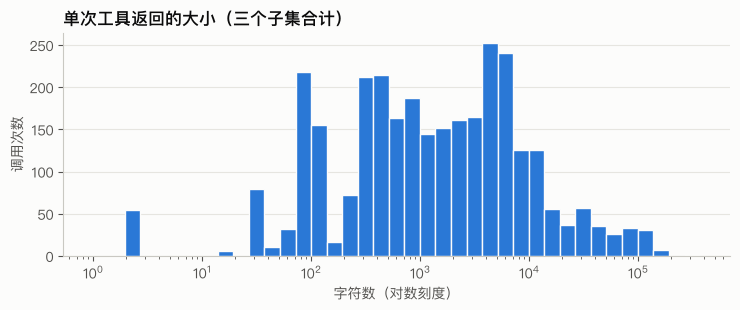

每个任务的工具返回总字符数：


,count,mean,std,min,50%,90%,max
子集,,,,,,,
单工具,145.0,3415.0,3597.0,2.0,2438.0,9329.0,14253.0
多工具,248.0,63834.0,66299.0,116.0,38885.0,169232.0,315053.0
多轮,219.0,20585.0,26808.0,31.0,11752.0,50466.0,184960.0


In [13]:
display(calls.groupby("子集")["返回字符数"].describe(percentiles=[0.5, 0.9, 0.99]).round(0))
fig, ax = plt.subplots(figsize=(7.5, 3.2))
v = calls["返回字符数"].clip(lower=1)
ax.hist(v, bins=np.logspace(0, np.log10(v.max()) + 0.1, 40), color=SERIES, edgecolor=SURFACE, linewidth=1)
ax.set_xscale("log")
ax.set_title("单次工具返回的大小（三个子集合计）")
ax.set_xlabel("字符数（对数刻度）")
ax.set_ylabel("调用次数")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

per_task = calls.groupby(["子集", "task_id"])["返回字符数"].sum().groupby("子集").describe(percentiles=[0.5, 0.9]).round(0)
print("每个任务的工具返回总字符数：")
per_task

In [14]:
def is_error(text):
    t = (text or "")[:400]
    return '"error"' in t or "未找到" in t or "失败" in t

err = []
for k, items in data.items():
    for i, t in enumerate(items):
        for c in finmcp.tool_calls(t):
            err.append({"子集": SPLITS[k], "报错": is_error(c["text"]), "非JSON": c["json"] is None})
err = pd.DataFrame(err)
err.groupby("子集")[["报错", "非JSON"]].mean().round(3)

,报错,非JSON
子集,,
单工具,0.000,0.000
多工具,0.003,0.001
多轮,0.011,0.000


## 8. 和我们研究直接相关：哪些任务含有语义判断

我们关心的是：参考轨迹里，下游参数有多少是"从上游返回的多个候选里挑出来的"。`finmcp.screen()` 对每个参数分类：

| 类别 | 含义 | 例子 |
| --- | --- | --- |
| 选一个 | 上游返回多个候选，只用了其中一个 | 12 个策略里选出客户说的那个 |
| 选一部分 | 上游返回多个候选，用了其中几个 | 98 只基金里挑出 20 只 |
| 全选 | 上游的候选全部用上（机械操作，不需要判断） | 把检索到的 5 只基金全部查详情 |
| 直接引用 | 上游只有一个值 | 方案编号 → 查方案详情 |

日期、小数、分页参数、以及客户原话里出现过的值都不算（它们不是"从候选里选"）。

In [15]:
scr = []
for k, items in data.items():
    for i, t in enumerate(items):
        s = finmcp.screen(t)
        scr.append({"子集": SPLITS[k], "task_id": f"{k}:{i}", "含语义判断": s["decision"],
                    **{name: s[key] > 0 for key, name in (("pick_one", "有选一个"), ("pick_subset", "有选一部分"),
                                                          ("pick_all", "有全选"), ("reference", "有直接引用"))}})
scr = pd.DataFrame(scr)
summary = scr.groupby("子集")[["含语义判断", "有选一个", "有选一部分", "有全选", "有直接引用"]].agg(["sum", "mean"])
summary.round(2)

含语义判断       有选一个       有选一部分        有全选       有直接引用      
      sum  mean  sum  mean   sum  mean  sum  mean   sum  mean
子集                                                           
单工具     0  0.00    0  0.00     0  0.00    0  0.00     0  0.00
多工具   110  0.44   69  0.28    76  0.31  124  0.50   165  0.66
多轮     50  0.23   17  0.08    36  0.16   23  0.11    89  0.41

In [16]:
dec = [{"task_id": f"multi_tool:{i}", **d} for i, t in enumerate(data["multi_tool"]) for d in finmcp.screen(t)["decisions"]]
dec = pd.DataFrame(dec)
print("多工具子集中的语义判断：", len(dec), "处；候选数中位数", dec["n_candidates"].median(), "，90 分位", dec["n_candidates"].quantile(0.9))
display(dec.groupby(["src_tool", "dst_tool"]).size().sort_values(ascending=False).head(12).rename("次数").to_frame())
dec[["task_id", "kind", "src_tool", "dst_tool", "dst_arg", "n_candidates", "chosen"]].head(10)

多工具子集中的语义判断： 197 处；候选数中位数 8.0 ，90 分位 23.0


次数
src_tool                      dst_tool                         
StrategySearchByKeyword       GetStrategyDetails             21
BatchGetStrategiesComposition BatchGetFundsDetail            10
StrategySearchByKeyword       BatchGetStrategiesComposition  10
BatchGetStrategiesComposition BatchGetFundsFeeRule            9
                              GetBatchFundPerformance         8
SearchFunds                   BatchGetFundsDetail             7
BatchGetStrategiesComposition GetFundAnnouncements            7
                              BatchGetFundNavHistory          6
BatchGetFundsDetail           GetFundAnnouncements            5
GetUserAssetView              GetStrategyAssetClassAnalysis   5
BatchGetStrategiesComposition BatchGetFundsHolding            5
GetBatchFundPerformance       BatchGetFundNavHistory          4

,task_id,kind,src_tool,dst_tool,dst_arg,n_candidates,chosen
0,multi_tool:1,pick_subset,StrategySearchByKeyword,GetStrategyDetails,strategyCodes,17,"[ZH158559, ZH158593, ZH159580]"
1,multi_tool:3,pick_one,StrategySearchByKeyword,GetStrategyDetails,strategyCodes,17,[ZH159580]
2,multi_tool:5,pick_one,SearchManagerViewpoint,BatchGetFundsDetail,fundCodes,2,[015979]
3,multi_tool:5,pick_one,SearchManagerViewpoint,SearchFunds,keyword,2,[750002]
4,multi_tool:11,pick_one,StrategySearchByKeyword,GetStrategyDetails,strategyCodes,12,[ZH000095]
5,multi_tool:16,pick_one,GetUserAssetView,GetStrategyRiskInfo,strategyCode,4,[ZH013136]
6,multi_tool:21,pick_subset,GetUserAssetView,GetStrategyAssetClassAnalysis,strategyCode,4,"[ZH013136, ZH032680]"
7,multi_tool:30,pick_subset,StrategySearchByKeyword,GetUserAssetHoldingDistribution,poCodes,12,"[LONG_WIN, ZH000095, ZH013136]"
8,multi_tool:31,pick_subset,GetUserAssetView,GetUserAssetHoldingDistribution,poCodes,11,"[ZH000193, ZH012636, ZH013136, ZH013804, ZH022440, ZH032680, ZH056464]"
9,multi_tool:34,pick_subset,SearchFunds,BatchGetFundsDetail,fundCodes,3,"[005801, 164824]"


最常见的语义判断就是"检索 → 挑选 → 批量查询"：从 `StrategySearchByKeyword` 或 `SearchFunds` 的结果里挑出符合客户意思的代码，再传给 `GetStrategyDetails`、`BatchGetFundsDetail` 等。候选数大多在几个到几十个之间，远在 Jev 的 255 个选项上限之内。

这也是 Jev-as-IF 的用武之地：这些挑选写成 `jev.choice` / `jev.filter`，程序就不必为了挑选再回到大模型。

## 9. 原论文怎么评测

论文只看**工具调用是否和参考轨迹一致**，不评回答质量：

| 指标 | 定义 |
| --- | --- |
| TR（工具召回率） | 预测对的工具数 ÷ 参考轨迹里的工具数 |
| TP（工具精确率） | 预测对的工具数 ÷ 预测的工具数 |
| TF1 | TR 与 TP 的调和平均 |
| EMR（精确匹配率） | 整条调用序列与参考完全一致的比例；同一步里的并行调用不计顺序 |

论文报告的结果（%，节选）：

In [17]:
paper = pd.DataFrame([
    ["DeepSeek-R1", 62.46, 49.31, 52.36, 4.85, 9.27, 0.00],
    ["GPT-OSS-20B", 22.57, 15.17, 38.54, 1.20, 7.38, 0.00],
    ["Seed-OSS-36B", 47.73, 35.17, 37.93, 3.61, 42.15, 2.17],
    ["Qwen3-4B-Thinking", 68.55, 65.52, 50.23, 4.82, 47.65, 2.26],
    ["Qwen3-30B-A3B-Thinking", 51.78, 55.17, 60.73, 7.47, 46.40, 4.10],
    ["Qwen3-235B-A22B-Thinking", 66.85, 60.00, 69.42, 10.62, 41.56, 3.08],
], columns=["模型", "单工具 TF1", "单工具 EMR", "多工具 TF1", "多工具 EMR", "多轮 TF1", "多轮 EMR"]).set_index("模型")
paper

,单工具 TF1,单工具 EMR,多工具 TF1,多工具 EMR,多轮 TF1,多轮 EMR
模型,,,,,,
DeepSeek-R1,62.46,49.31,52.36,4.85,9.27,0.00
GPT-OSS-20B,22.57,15.17,38.54,1.20,7.38,0.00
Seed-OSS-36B,47.73,35.17,37.93,3.61,42.15,2.17
Qwen3-4B-Thinking,68.55,65.52,50.23,4.82,47.65,2.26
Qwen3-30B-A3B-Thinking,51.78,55.17,60.73,7.47,46.40,4.10
Qwen3-235B-A22B-Thinking,66.85,60.00,69.42,10.62,41.56,3.08


**怎么理解这些数字**

- 多工具和多轮的 EMR 都在 10% 上下或更低。原因之一是参考轨迹本身不唯一：换一个同样合理的检索词或挑选，EMR 就判错。
- 所以我们的实验**不直接沿用 EMR**，而是用回答质量（大模型裁判对照参考答案）加上调用次数、token、延迟；同时报告调用是否在回放里命中，作为参考。
- 参考轨迹由 Qwen3-235B 生成，它在自家轨迹上占优势。我们的主规划模型避开它。

## 10. 小结：对我们的实验意味着什么

1. **单工具来自真实日志，多工具和多轮是合成的**。参考轨迹是"一个合理答案"，不是唯一答案。
2. **工具返回是真实的**，而且很大（多工具任务的返回总量中位数在几万字符），这正是 ReAct 多轮重读的成本来源。
3. **数据集不含工具参数定义**。要么开通且慢 MCP 拿正式定义，要么像 02 号 notebook 那样从日志反推。
4. **语义判断很常见**：多工具子集里近一半任务含有"从候选里挑选"的步骤，模式高度集中在"检索 → 挑选 → 批量查询"。
5. **评测要换口径**：原论文的 EMR 不适合比较"走法不同但结果正确"的方法。
6. **许可证是 CC BY-NC-SA 4.0**：论文研究可以用，基于它做的评测集要以相同许可发布；商业场景使用前要确认。